In [8]:
import datetime
import numpy as np
import pandas as pd
import lseg.data as ld
import matplotlib.pyplot as plt

In [9]:
ld.open_session()

df = ld.get_history(
    universe="EUR=",
    fields=["MID_PRICE"],
    interval="30min",
    start=datetime.datetime.now() - datetime.timedelta(14),
    end=datetime.datetime.now()
)

df

EUR=,MID_PRICE
Timestamp,
2026-07-17 19:30:00,1.14415
2026-07-17 20:00:00,1.14375
2026-07-17 20:30:00,1.14395
2026-07-19 19:00:00,1.1431
2026-07-19 19:30:00,1.14265
...,...
2026-07-31 08:00:00,1.15075
2026-07-31 08:30:00,1.15235
2026-07-31 09:00:00,1.1509


In [10]:
df["RETURNS"] = df["MID_PRICE"].pct_change()
df = df.dropna()

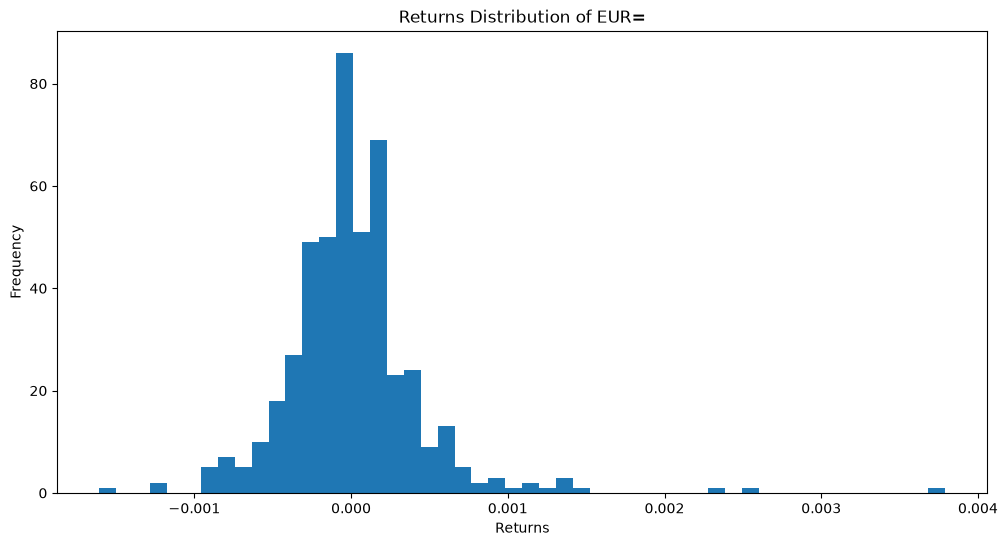

In [11]:
plt.figure(figsize=(12,6))
plt.hist(df["RETURNS"], bins=50)

plt.title(f"Returns Distribution of {df.columns.name}")
plt.xlabel("Returns")
plt.ylabel("Frequency")
plt.show()


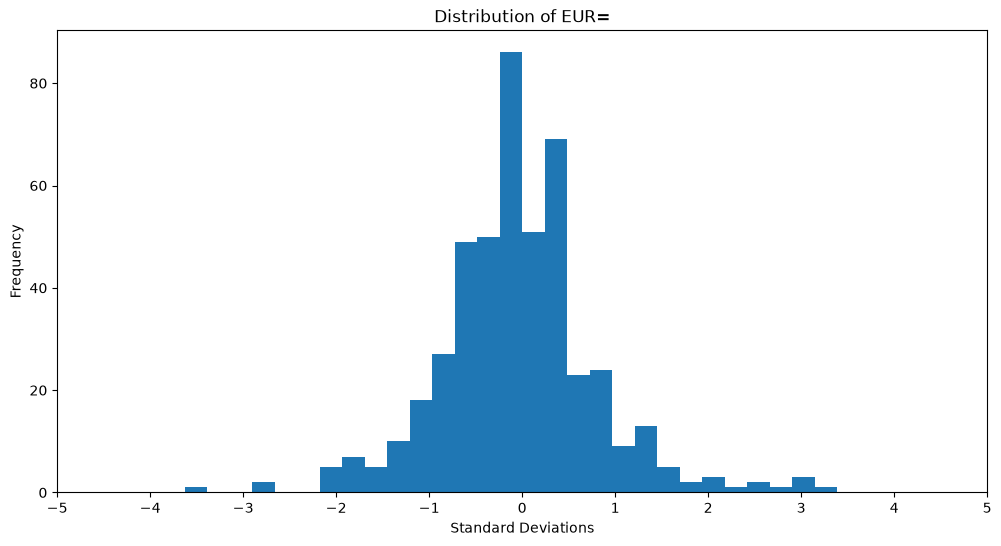

[Error 400] - {'error': 'invalid_grant'}


In [12]:
df = df.copy()
df["STD_DEV"] = (df["RETURNS"] - df["RETURNS"].mean()) / df["RETURNS"].std()

plt.figure(figsize=(12,6))
plt.hist(df["STD_DEV"], bins=50)
plt.xlim(-5, 5)
plt.xticks(range(-5, 6, 1))

plt.title(f"Distribution of {df.columns.name}")
plt.xlabel("Standard Deviations")
plt.ylabel("Frequency")
plt.show()